# Bab 7: Unsupervised Learning

Notebook ini merangkum Bab 7 buku *Practical Statistics for Data Scientists* (Bruce, Bruce & Gedeck).

## Apa itu unsupervised learning?

Di Bab 4 sampai 6 kita melakukan **supervised learning**: ada kolom jawaban (misalnya gagal bayar atau lunas) dan kita melatih model supaya bisa menebak jawaban itu dari kolom-kolom lain.

Di **unsupervised learning** tidak ada kolom jawaban. Kita hanya punya tumpukan data dan bertanya, "Pola apa yang tersembunyi di sini?" Bayangkan kita diberi seratus kancing campur aduk tanpa label. Tidak ada yang bilang mana kancing baju dan mana kancing jaket, tapi kita bisa mengelompokkannya sendiri berdasarkan ukuran, warna, dan jumlah lubangnya.

Tujuan umumnya ada tiga:

1. **Mengelompokkan data** (clustering), misalnya mengelompokkan pengunjung website jadi beberapa tipe supaya tampilan situs bisa disesuaikan.
2. **Merangkum banyak variabel jadi sedikit** (reduksi dimensi), misalnya dari ribuan sensor pabrik jadi beberapa indikator utama.
3. **Eksplorasi data** ketika variabel dan barisnya terlalu banyak untuk dilihat satu per satu.

Unsupervised learning juga berguna untuk prediksi. Contohnya pada masalah **cold start**: kita meluncurkan kampanye baru atau mencari jenis penipuan baru, dan belum punya data jawaban. Clustering membantu kita mulai belajar dengan mengelompokkan populasi lebih dulu.

Isi notebook:

1. Principal Components Analysis (PCA)
2. K-Means Clustering
3. Hierarchical Clustering
4. Model-Based Clustering
5. Scaling dan Variabel Kategorikal

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn import preprocessing
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

sns.set_style("whitegrid")
pd.set_option("display.precision", 4)

BASE = "https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/"

# Return harian saham S&P 500 (baris = tanggal, kolom = kode saham)
sp500_px = pd.read_csv(BASE + "sp500_data.csv.gz", index_col=0)

# Data pinjaman (dipakai di bagian scaling)
loan_data = pd.read_csv(BASE + "loan_data.csv.gz", index_col=0)
loan_data = loan_data.drop(columns=["status"])

sp500_px.shape, loan_data.shape

((5647, 517), (45342, 19))

## 1. Principal Components Analysis (PCA)

### Ide dasarnya

Sering kali beberapa variabel bergerak bersama. Contohnya total tagihan restoran dan tip: kalau tagihan naik, tip biasanya ikut naik. Sebagian informasi di variabel kedua sebenarnya sudah ada di variabel pertama (redundan).

**PCA** adalah cara menemukan pola "bergerak bersama" ini. Ia merangkum beberapa variabel numerik menjadi sedikit variabel baru yang disebut **principal component**. Tiap komponen adalah campuran berbobot dari variabel asli. Komponen pertama menangkap variasi terbesar, komponen kedua menangkap variasi terbesar yang tersisa, dan seterusnya.

Analogi: bayangkan awan titik berbentuk lonjong, seperti telur. Komponen pertama adalah garis panjang telur, dan komponen kedua adalah garis lebar telur yang tegak lurus dengannya. Kalau kita hanya boleh memakai satu garis untuk menggambarkan telur, kita pilih garis panjang karena ia menangkap sebagian besar bentuknya.

Istilah penting:

- **Principal component**: kombinasi linear dari variabel prediktor.
- **Loadings** (bobot): angka pengali yang mengubah variabel asli menjadi komponen. Loading menunjukkan variabel mana yang berkontribusi besar ke suatu komponen.
- **Screeplot**: grafik varians tiap komponen, untuk melihat seberapa penting masing-masing.

PCA pertama kali diusulkan oleh Karl Pearson, dan bisa dilihat sebagai versi unsupervised dari linear discriminant analysis.

### Contoh sederhana: dua saham minyak

Kita pakai return harian Chevron (CVX) dan ExxonMobil (XOM). Dengan dua variabel akan ada dua komponen.

In [2]:
oil_px = sp500_px.loc[sp500_px.index >= "2011-01-01", ["CVX", "XOM"]]

pcs = PCA(n_components=2)
pcs.fit(oil_px)

loadings = pd.DataFrame(pcs.components_, columns=oil_px.columns)
loadings

,CVX,XOM
0,0.8287,0.5597
1,-0.5597,0.8287


Cara membacanya (angka persis bisa sedikit berbeda dari buku, yang mencatat bobot sekitar −0,747 dan −0,665 untuk komponen pertama dan 0,665 dan −0,747 untuk komponen kedua):

- **Komponen pertama**: kedua bobot bertanda sama, jadi komponen ini pada dasarnya adalah *rata-rata* CVX dan XOM. Ia mewakili kenyataan bahwa kedua perusahaan energi ini bergerak searah.
- **Komponen kedua**: bobotnya berlawanan tanda, jadi ia mengukur *selisih*, yaitu saat harga kedua saham bergerak berlainan arah.

Tanda negatif tidak perlu dikhawatirkan. Membalik tanda semua bobot pada satu komponen tidak mengubah arti komponen itu, sama seperti garis yang melewati titik (0,0) dan (1,1) sama dengan garis yang melewati (0,0) dan (−1,−1).

Mari kita gambar kedua komponen di atas datanya.

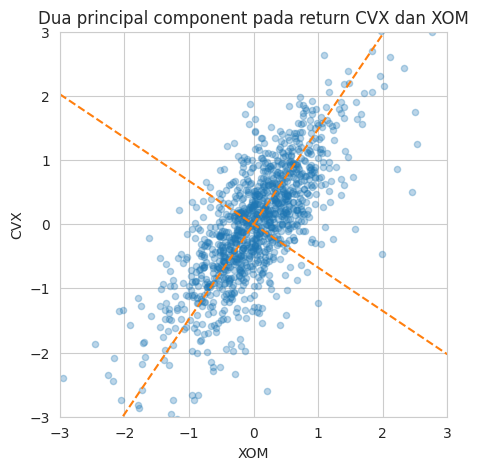

In [3]:
def abline(slope, intercept, ax):
    """Koordinat garis berdasarkan slope dan intercept."""
    x_vals = np.array(ax.get_xlim())
    return (x_vals, intercept + slope * x_vals)


ax = oil_px.plot.scatter(x="XOM", y="CVX", alpha=0.3, figsize=(5, 5))
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.plot(*abline(loadings.loc[0, "CVX"] / loadings.loc[0, "XOM"], 0, ax), "--", color="C1")
ax.plot(*abline(loadings.loc[1, "CVX"] / loadings.loc[1, "XOM"], 0, ax), "--", color="C1")
ax.set_title("Dua principal component pada return CVX dan XOM")
plt.show()

Garis putus-putus pertama mengikuti sumbu panjang awan titik, yaitu arah komponen pertama. Garis kedua mengikuti sumbu pendeknya. Sebagian besar variasi ada di sepanjang garis pertama, masuk akal karena saham energi cenderung bergerak berkelompok.

### Menghitung komponen untuk banyak variabel

Dari dua variabel ke banyak variabel prosesnya sama saja:

1. Komponen pertama dicari sebagai kombinasi linear variabel yang menjelaskan **persentase varians total terbesar**.
2. Komponen kedua dicari dengan bobot berbeda, dengan syarat tidak berkorelasi dengan komponen pertama.
3. Proses berlanjut sampai jumlah komponen sama dengan jumlah variabel asli.
4. Kita pilih sebanyak mungkin komponen yang cukup untuk menjelaskan "sebagian besar" varians.
5. Terakhir, data asli diubah menjadi **skor komponen** dengan menerapkan bobot tadi. Skor inilah yang dipakai sebagai pengganti variabel asli.

Perhitungannya klasik dan cepat, tanpa iterasi. Catatan: PCA hanya bekerja untuk variabel **numerik**.

### Menafsirkan komponen: screeplot dan loadings

Kita pakai 16 saham besar dari berbagai sektor.

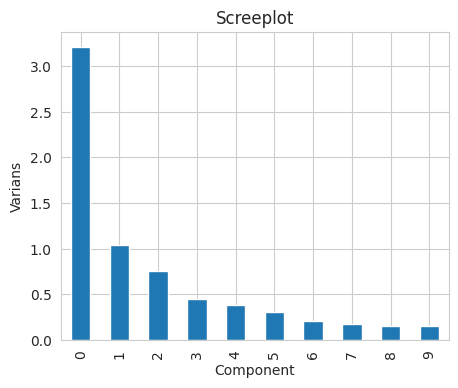

In [4]:
syms = sorted(["AAPL", "MSFT", "CSCO", "INTC", "CVX", "XOM", "SLB", "COP",
               "JPM", "WFC", "USB", "AXP", "WMT", "TGT", "HD", "COST"])
top_sp = sp500_px.loc[sp500_px.index >= "2011-01-01", syms]

sp_pca = PCA()
sp_pca.fit(top_sp)

explained_variance = pd.DataFrame(sp_pca.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(5, 4))
ax.set_xlabel("Component")
ax.set_ylabel("Varians")
ax.set_title("Screeplot")
plt.show()

**Screeplot** dibaca seperti lereng gunung: batang pertama (komponen 1) biasanya menjulang tinggi, lalu menurun cepat ke batang-batang kecil di kaki lereng. Komponen yang tingginya sudah rendah sekali menambah sedikit informasi.

**Berapa komponen yang dipilih?** Tidak ada aturan baku. Cara umumnya:

- Lihat screeplot dan potong di titik ketika batang mulai landai.
- Pilih jumlah komponen sampai varians kumulatif melewati ambang tertentu, misalnya 80%.
- Periksa loadings: apakah komponen itu bisa ditafsirkan masuk akal?
- Cara yang lebih formal: cross-validation.

Selanjutnya kita lihat bobot (loadings) lima komponen teratas.

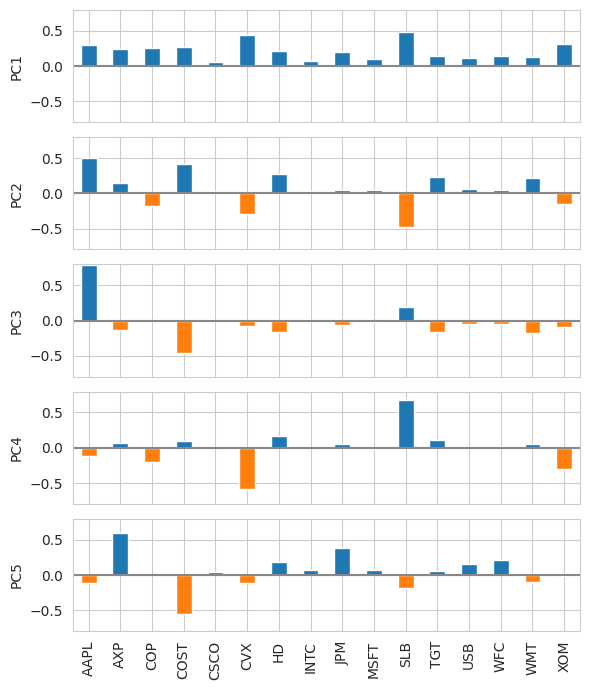

In [5]:
loadings = pd.DataFrame(sp_pca.components_[0:5, :], columns=top_sp.columns)
maxPC = 1.01 * np.max(np.max(np.abs(loadings.loc[0:5, :])))

f, axes = plt.subplots(5, 1, figsize=(6, 7), sharex=True)
for i, ax in enumerate(axes):
    pc_loadings = loadings.loc[i, :]
    colors = ["C0" if l > 0 else "C1" for l in pc_loadings]
    ax.axhline(color="#888888")
    pc_loadings.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f"PC{i+1}")
    ax.set_ylim(-maxPC, maxPC)
plt.tight_layout()
plt.show()

Hasil di buku menunjukkan pola yang bisa diceritakan:

- **Komponen 1**: semua bobot bertanda sama. Ini khas data ketika semua kolom dipengaruhi satu faktor bersama, di sini tren pasar secara keseluruhan.
- **Komponen 2**: kontras saham energi terhadap saham lain.
- **Komponen 3**: terutama kontras pergerakan Apple dan Costco.
- **Komponen 4**: kontras Schlumberger (SLB) terhadap saham energi lain.
- **Komponen 5**: didominasi perusahaan keuangan.

Jadi PCA tidak sekadar memadatkan data, tapi juga membantu kita menemukan "cerita" di balik data.

### Correspondence analysis (untuk data kategorikal)

PCA tidak bisa dipakai untuk data kategorikal. Teknik yang agak mirip adalah **correspondence analysis**. Tujuannya melihat keterkaitan antar kategori. Masukannya berupa tabel silang (baris satu variabel, kolom variabel lain, isinya jumlah kejadian), dan keluarannya **biplot**: diagram titik yang kategorinya mendekat jika berasosiasi.

Contoh di buku: tugas rumah tangga (mencuci, memasak, memperbaiki, dst.) dibandingkan dengan siapa yang mengerjakan (istri, suami, bergantian, bersama). Teknik ini terutama dipakai untuk analisis grafis data kategorikal berdimensi rendah, bukan sebagai langkah reduksi dimensi pada big data seperti PCA.

Buku memakai paket `prince`. Supaya tidak perlu memasang paket tambahan, di bawah ini correspondence analysis dihitung langsung dengan SVD (cara kerjanya sama di balik layar).

In [6]:
housetasks = pd.read_csv(BASE + "housetasks.csv", index_col=0)
housetasks

,Wife,Alternating,Husband,Jointly
Task,,,,
Laundry,156,14,2,4
Main_meal,124,20,5,4
Dinner,77,11,7,13
Breakfast,82,36,15,7
Tidying,53,11,1,57
Dishes,32,24,4,53
Shopping,33,23,9,55
Official,12,46,23,15
Driving,10,51,75,3


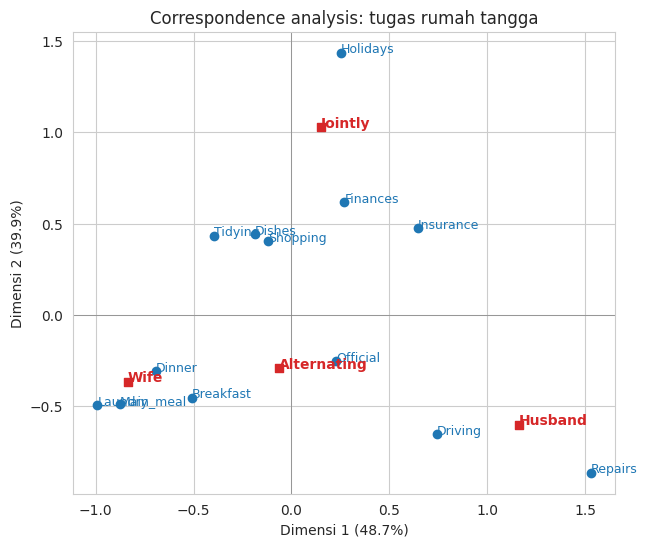

In [7]:
# Correspondence analysis sederhana lewat SVD
N = housetasks.values.astype(float)
P = N / N.sum()
r = P.sum(axis=1)                      # massa baris
c = P.sum(axis=0)                      # massa kolom

# Residual terstandardisasi
S = np.diag(1 / np.sqrt(r)) @ (P - np.outer(r, c)) @ np.diag(1 / np.sqrt(c))
U, sv, Vt = np.linalg.svd(S, full_matrices=False)

row_coords = np.diag(1 / np.sqrt(r)) @ U * sv        # koordinat baris (tugas)
col_coords = np.diag(1 / np.sqrt(c)) @ Vt.T * sv     # koordinat kolom (pelaku)
inertia = sv ** 2 / np.sum(sv ** 2)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(row_coords[:, 0], row_coords[:, 1], c="C0")
for name, (x, y) in zip(housetasks.index, row_coords[:, :2]):
    ax.annotate(name, (x, y), color="C0", fontsize=9)
ax.scatter(col_coords[:, 0], col_coords[:, 1], c="C3", marker="s")
for name, (x, y) in zip(housetasks.columns, col_coords[:, :2]):
    ax.annotate(name, (x, y), color="C3", fontsize=10, fontweight="bold")
ax.axhline(0, color="gray", lw=0.5)
ax.axvline(0, color="gray", lw=0.5)
ax.set_xlabel(f"Dimensi 1 ({inertia[0]*100:.1f}%)")
ax.set_ylabel(f"Dimensi 2 ({inertia[1]*100:.1f}%)")
ax.set_title("Correspondence analysis: tugas rumah tangga")
plt.show()

Cara membaca biplot: titik yang berdekatan berasosiasi. Tugas yang dekat dengan "Wife" umumnya dikerjakan istri, yang dekat dengan "Husband" dikerjakan suami. Satuan sumbunya tidak punya arti langsung terhadap data asli. Nilai utama plot ini adalah menunjukkan secara visual variabel mana yang saling berhubungan.

**Ide kunci PCA:**

- Principal component adalah kombinasi linear dari variabel prediktor (hanya numerik).
- Komponen dihitung agar tidak berkorelasi satu sama lain, sehingga redundansi berkurang.
- Biasanya sedikit komponen sudah menjelaskan sebagian besar varians.
- Komponen-komponen itu bisa menggantikan variabel asli yang jumlahnya lebih banyak.
- Correspondence analysis adalah teknik serupa untuk data kategorikal, tetapi kurang berguna di konteks big data.

## 2. K-Means Clustering

### Ide dasarnya

**Clustering** membagi data menjadi kelompok-kelompok, dengan anggota dalam satu kelompok mirip satu sama lain. Hasilnya bisa dianalisis lebih jauh, atau dipakai sebagai fitur/outcome untuk model prediksi. K-means adalah metode clustering pertama dan masih sangat populer, karena algoritmanya sederhana dan bisa menangani data yang besar.

Istilah penting:

- **Cluster**: kelompok record yang mirip.
- **Cluster mean** (pusat cluster): vektor rata-rata semua variabel untuk record di cluster itu.
- **K**: jumlah cluster yang kita minta.

Analogi: kita ingin membagi 100 toko ke dalam 4 wilayah distribusi. Kita taruh 4 gudang di posisi acak, tiap toko dilayani gudang terdekat, lalu kita pindahkan tiap gudang ke titik tengah toko-toko yang dilayaninya. Ulangi sampai tidak ada toko yang berpindah gudang. Itulah K-means.

K-means mencari pembagian yang meminimalkan **within-cluster sum of squares**: jumlah kuadrat jarak tiap record ke pusat cluster-nya. Ukuran cluster tidak dijamin sama.

> **Normalisasi**: variabel kontinu biasanya distandardisasi (kurangi rata-rata, bagi simpangan baku). Kalau tidak, variabel berskala besar akan mendominasi proses clustering.

### Contoh sederhana: return XOM dan CVX dalam 4 cluster

Return harian saham sudah berada pada skala yang sebanding, sehingga tidak perlu dinormalisasi.

In [8]:
df = sp500_px.loc[sp500_px.index >= "2011-01-01", ["XOM", "CVX"]].copy()

kmeans = KMeans(n_clusters=4, n_init=10, random_state=1).fit(df)

df["cluster"] = kmeans.labels_
df.head()

,XOM,CVX,cluster
2011-01-03,0.7368,0.2407,3
2011-01-04,0.1687,-0.5845,0
2011-01-05,0.0266,0.4470,3
2011-01-06,0.2486,-0.9198,0
2011-01-07,0.3373,0.1805,3


In [9]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=["XOM", "CVX"])
centers

,XOM,CVX
0,-0.3285,-0.5669
1,-1.1440,-1.7503
2,0.9583,1.3742
3,0.2420,0.3352


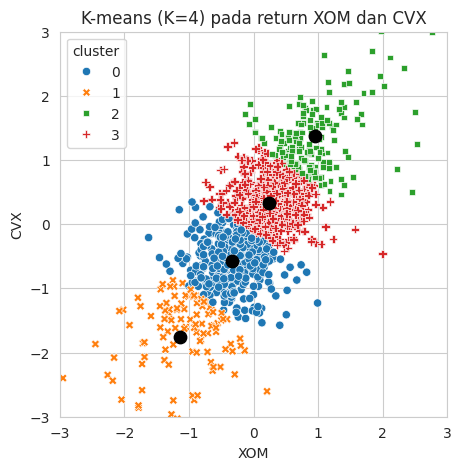

In [10]:
fig, ax = plt.subplots(figsize=(5, 5))
ax = sns.scatterplot(x="XOM", y="CVX", hue="cluster", style="cluster",
                     palette="tab10", ax=ax, data=df)
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
centers.plot.scatter(x="XOM", y="CVX", ax=ax, s=80, color="black")
ax.set_title("K-means (K=4) pada return XOM dan CVX")
plt.show()

Dua cluster mewakili hari ketika pasar saham energi turun ("down"), dan dua lainnya hari ketika naik ("up"). Perhatikan juga bahwa K-means tetap membagi data ke cluster walaupun kelompoknya tidak terpisah jelas. Itu bisa berguna kalau kita memang perlu membagi record secara optimal menjadi beberapa grup.

Karena K-means memulai dari titik acak, hasilnya bisa berbeda tiap dijalankan. Kita sebaiknya memeriksa bahwa perbedaannya tidak terlalu besar.

### Cara kerja algoritma

Untuk data dengan p variabel, mencari solusi persis sangat sulit secara komputasi, jadi dipakai algoritma heuristik yang menemukan solusi yang optimal secara lokal:

1. Tentukan K dan pusat cluster awal (biasanya dengan menetapkan tiap record ke cluster acak lalu menghitung rata-ratanya).
2. **Assign**: tempatkan tiap record ke pusat cluster terdekat (jarak kuadrat).
3. **Update**: hitung pusat cluster baru dari anggota masing-masing.
4. Ulangi langkah 2 dan 3 sampai penetapan cluster tidak berubah lagi (konvergen).

Karena hasil bisa terjebak di solusi yang kurang bagus, algoritma dijalankan beberapa kali dengan titik awal berbeda, dan yang dipilih adalah yang **within-cluster sum of squares-nya paling rendah**. Di scikit-learn, jumlah percobaan diatur lewat `n_init`, dan batas iterasi lewat `max_iter` (bawaan 300).

Kita coba dengan 16 saham dan 5 cluster.

In [11]:
top_sp = sp500_px.loc[sp500_px.index >= "2011-01-01", syms]

kmeans = KMeans(n_clusters=5, n_init=10, random_state=1).fit(top_sp)

# Ukuran tiap cluster
Counter(kmeans.labels_)

Counter({np.int32(1): 301,
         np.int32(0): 272,
         np.int32(4): 287,
         np.int32(2): 158,
         np.int32(3): 113})

### Menafsirkan cluster

Dua keluaran terpenting K-means adalah **ukuran cluster** dan **rata-rata cluster**. Ukuran yang timpang sering menandakan ada outlier jauh atau kelompok yang sangat berbeda dari data lain, dan itu layak diperiksa.

Rata-rata cluster bisa digambarkan seperti loadings PCA.

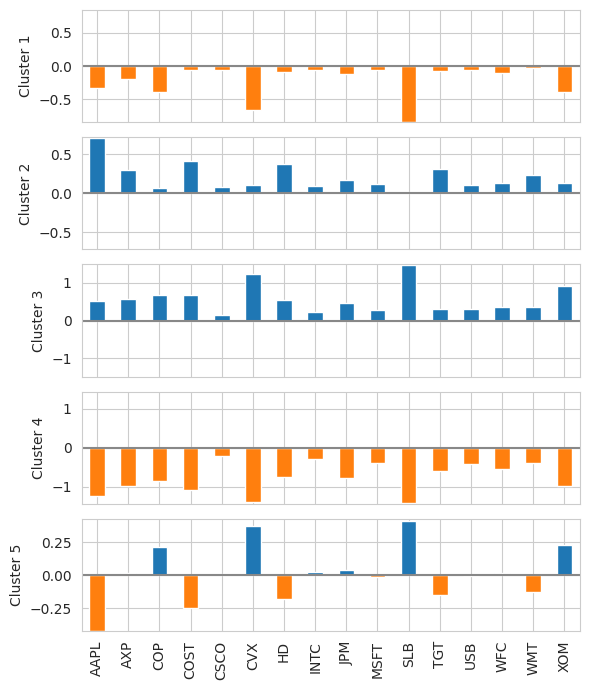

In [12]:
centers = pd.DataFrame(kmeans.cluster_centers_, columns=syms)

f, axes = plt.subplots(5, 1, figsize=(6, 7), sharex=True)
for i, ax in enumerate(axes):
    center = centers.loc[i, :]
    maxPC = 1.01 * np.max(np.max(np.abs(center)))
    colors = ["C0" if l > 0 else "C1" for l in center]
    ax.axhline(color="#888888")
    center.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f"Cluster {i + 1}")
    ax.set_ylim(-maxPC, maxPC)
plt.tight_layout()
plt.show()

Di buku, cluster 4 dan 5 adalah hari ketika pasar turun dan naik. Cluster 2 dan 3 menandai hari saham konsumen naik dan saham energi turun, dan cluster 1 kebalikannya (energi naik, konsumen turun). Urutan nomor cluster di komputer kita bisa berbeda karena sifat acak K-means, tapi polanya akan serupa.

> **Cluster vs PCA**: grafik rata-rata cluster mirip dengan loadings PCA, tetapi ada beda penting. Pada PCA, tanda (plus atau minus) bobot tidak punya makna mutlak. Pada cluster, tandanya bermakna. PCA mencari arah variasi utama, sedangkan clustering mencari kelompok record yang berdekatan.

### Memilih jumlah cluster (K)

K-means mengharuskan kita menentukan K. Kadang K ditentukan kebutuhan bisnis. Misalnya tim sales ingin membagi pelanggan jadi beberapa "persona": dua mungkin terlalu sedikit untuk membedakan, delapan mungkin terlalu banyak untuk dikelola.

Kalau tidak ada patokan seperti itu, cara yang umum adalah **elbow method**: lihat bagaimana varians yang dijelaskan bertambah saat K naik. Awalnya naik tajam, lalu melandai. Titik "siku" (tempat grafik mulai landai) adalah kandidat K. Di data yang kelompoknya tidak jelas, sikunya sering tidak tampak, dan itu juga informasi tentang sifat data.

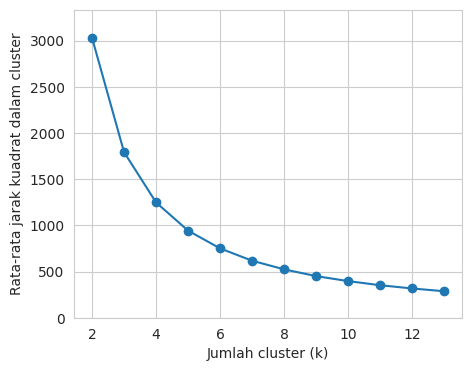

In [13]:
inertia = []
for n_clusters in range(2, 14):
    km = KMeans(n_clusters=n_clusters, n_init=10, random_state=0).fit(top_sp)
    inertia.append(km.inertia_ / n_clusters)

inertias = pd.DataFrame({"n_clusters": range(2, 14), "inertia": inertia})

ax = inertias.plot(x="n_clusters", y="inertia", marker="o", figsize=(5, 4))
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Rata-rata jarak kuadrat dalam cluster")
plt.ylim((0, 1.1 * inertias.inertia.max()))
ax.legend().set_visible(False)
plt.show()

Tes terpenting untuk jumlah cluster adalah: seberapa besar kemungkinan cluster itu muncul lagi pada data baru? Apakah cluster-nya bisa ditafsirkan dan terkait karakteristik umum data, atau hanya mencerminkan data tertentu ini? Cross-validation bisa membantu menilainya. Tidak ada satu aturan yang selalu benar untuk menentukan jumlah cluster. Ada juga cara yang lebih formal, misalnya statistik "gap", tetapi untuk kebanyakan aplikasi pendekatan teoretis itu tidak diperlukan.

**Ide kunci K-means:**

- Jumlah cluster K ditentukan pengguna.
- Algoritma membentuk cluster dengan berulang kali menetapkan record ke pusat cluster terdekat sampai tidak ada perubahan.
- Pertimbangan praktis biasanya lebih menentukan pilihan K daripada statistik.

## 3. Hierarchical Clustering

### Ide dasarnya

Hierarchical clustering adalah alternatif K-means yang bisa menghasilkan kelompok yang sangat berbeda. Kelebihannya: kita bisa **melihat** efek memilih jumlah cluster yang berbeda, ia lebih peka terhadap kelompok atau record yang aneh (outlier), dan hasilnya punya tampilan grafis yang intuitif.

Kekurangannya: tidak cocok untuk data besar. Bahkan pada puluhan ribu record, kebutuhan komputasinya sudah berat, sehingga umumnya dipakai untuk dataset kecil.

Istilah penting:

- **Dendrogram**: diagram pohon yang menunjukkan record dan hierarki cluster-nya.
- **Distance**: ukuran kedekatan antara dua record.
- **Dissimilarity**: ukuran kedekatan antara dua cluster.

Dua bahan dasarnya: metrik jarak d(i, j) antar dua record, dan metrik dissimilarity D(A, B) antar dua cluster yang dihitung dari jarak anggota-anggotanya.

### Contoh: mengelompokkan saham

Berbeda dari contoh K-means yang mengelompokkan *hari*, di sini kita mengelompokkan *perusahaan*. Algoritma clustering mengelompokkan baris, jadi data harus di-transpose supaya baris = saham dan kolom = tanggal.

In [14]:
syms1 = ["AAPL", "AMZN", "AXP", "COP", "COST", "CSCO", "CVX", "GOOGL", "HD",
         "INTC", "JPM", "MSFT", "SLB", "TGT", "USB", "WFC", "WMT", "XOM"]

df = sp500_px.loc[sp500_px.index >= "2011-01-01", syms1].transpose()
df.shape   # (18 saham, banyak tanggal)

(18, 1131)

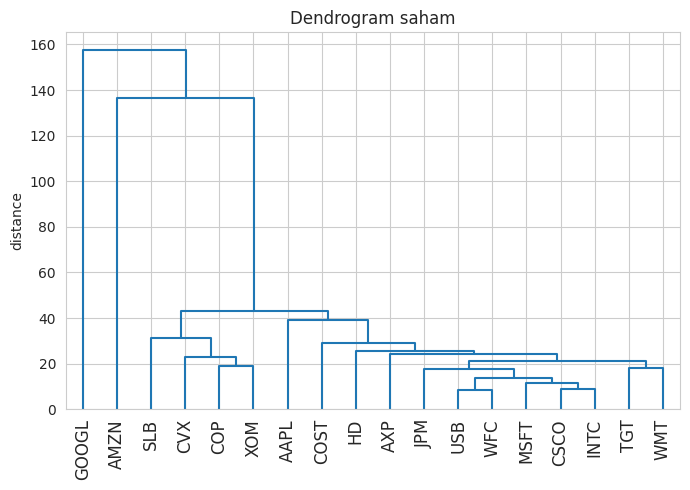

In [15]:
Z = linkage(df, method="complete")

fig, ax = plt.subplots(figsize=(7, 5))
dendrogram(Z, labels=df.index, ax=ax, color_threshold=0)
plt.xticks(rotation=90)
ax.set_ylabel("distance")
ax.set_title("Dendrogram saham")
plt.tight_layout()
plt.show()

### Cara membaca dendrogram

Daun-daun di bawah adalah record (di sini saham). Tinggi cabang menunjukkan seberapa berbeda dua kelompok saat digabung: makin tinggi, makin berbeda. Di hasil buku, Google dan Amazon cukup berbeda satu sama lain dan dari saham lain, saham minyak (SLB, CVX, XOM, COP) membentuk kelompok tersendiri, Apple berdiri sendiri, dan sisanya mirip satu sama lain.

Berbeda dari K-means, kita **tidak perlu menentukan jumlah cluster di awal**. Bayangkan garis horizontal yang digeser naik-turun: setiap kali garis itu memotong garis vertikal, itu satu cluster. Untuk mengambil jumlah cluster tertentu, pakai `fcluster`.

In [16]:
memb = fcluster(Z, 4, criterion="maxclust")
memb = pd.Series(memb, index=df.index)

for key, item in memb.groupby(memb):
    print(f"{key} : {', '.join(item.index)}")

1 : COP, CVX, SLB, XOM
2 : AAPL, AXP, COST, CSCO, HD, INTC, JPM, MSFT, TGT, USB, WFC, WMT
3 : AMZN
4 : GOOGL


### Algoritma agglomerative

Algoritma utama hierarchical clustering adalah **agglomerative**, yang bekerja dari bawah ke atas:

1. Mulai dengan tiap record sebagai cluster sendiri.
2. Hitung dissimilarity antar semua pasangan cluster.
3. Gabungkan dua cluster yang paling mirip (dissimilarity terkecil).
4. Kalau masih ada lebih dari satu cluster, kembali ke langkah 2. Kalau tidak, selesai.

Analoginya seperti turnamen yang berjalan terbalik: awalnya semua orang berdiri sendiri, lalu yang paling dekat pertemanannya bergabung jadi kelompok kecil, kelompok kecil bergabung jadi kelompok besar, sampai semuanya satu kelompok.

### Ukuran dissimilarity

Ada empat ukuran yang umum:

| Ukuran | Cara kerja | Kecenderungan |
|---|---|---|
| **Complete linkage** | jarak *terjauh* antara anggota dua cluster | cluster yang anggotanya mirip |
| **Single linkage** | jarak *terdekat* antara anggota dua cluster | "rakus", cluster bisa berisi anggota yang sangat beragam |
| **Average linkage** | rata-rata semua pasangan jarak | kompromi single dan complete |
| **Minimum variance (Ward)** | meminimalkan within-cluster sum of squares | mirip K-means |

Berikut perbandingan keempatnya pada return XOM dan CVX dengan 4 cluster. Kita pakai sampel 300 hari saja agar tidak berat.

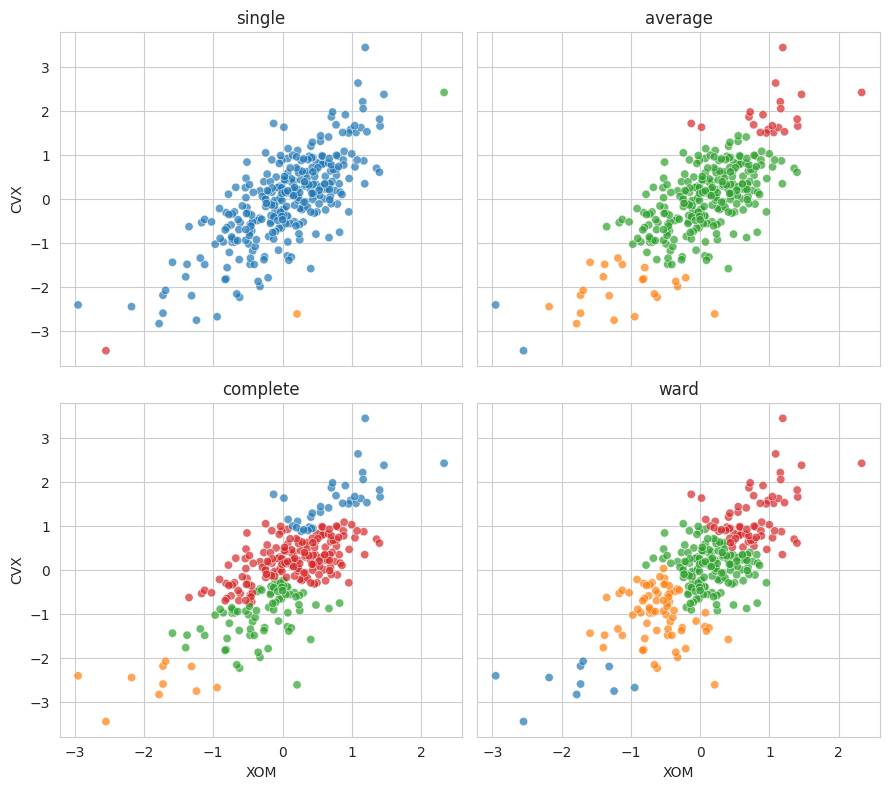

In [17]:
df_xc = sp500_px.loc[sp500_px.index >= "2011-01-01", ["XOM", "CVX"]].sample(300, random_state=1)

fig, axes = plt.subplots(2, 2, figsize=(9, 8), sharex=True, sharey=True)
for ax, method in zip(axes.ravel(), ["single", "average", "complete", "ward"]):
    Zm = linkage(df_xc, method=method)
    labels = fcluster(Zm, 4, criterion="maxclust")
    sns.scatterplot(x=df_xc["XOM"], y=df_xc["CVX"], hue=labels, palette="tab10",
                    ax=ax, legend=False, alpha=0.7)
    ax.set_title(method)
plt.tight_layout()
plt.show()

Hasilnya sangat berbeda antar ukuran. Single linkage cenderung memasukkan hampir semua titik ke satu cluster. Kecuali Ward, semua ukuran menghasilkan setidaknya satu cluster yang hanya berisi sedikit titik pencilan. Metode Ward paling mirip dengan hasil K-means.

**Ide kunci hierarchical clustering:**

- Dimulai dengan tiap record sebagai satu cluster.
- Cluster digabungkan dengan tetangga terdekat sampai semuanya satu cluster (algoritma agglomerative).
- Riwayat penggabungan disimpan dan digambar, jadi kita bisa melihat jumlah dan struktur cluster pada berbagai tahap tanpa menentukan jumlahnya di awal.
- Jarak antar cluster dihitung dengan beberapa cara, semuanya berdasar jarak antar record.

## 4. Model-Based Clustering

K-means dan hierarchical clustering berbasis heuristik: mereka mencari kelompok yang anggotanya *dekat* satu sama lain, diukur langsung dari data, tanpa model probabilitas. **Model-based clustering** berbeda: ia berlandaskan teori statistik dan menyediakan cara yang lebih ketat untuk menentukan sifat dan jumlah cluster. Misalnya ia bisa menangani satu kelompok yang anggotanya mirip tetapi tidak harus berdekatan (saham teknologi dengan return sangat bervariasi), di samping kelompok lain yang mirip dan juga berdekatan (saham utilitas yang stabil).

### Distribusi normal multivariat

Metode yang paling banyak dipakai bertumpu pada **distribusi normal multivariat**, yaitu generalisasi distribusi normal (kurva lonceng) ke banyak variabel sekaligus. Distribusi ini ditentukan oleh dua hal:

- vektor **rata-rata** tiap variabel, dan
- **matriks kovarians** Σ, yang menggambarkan bagaimana variabel saling berkorelasi (variansi di diagonal, kovarians di luar diagonal).

Lewat kontur probabilitas, distribusi ini tampak seperti lingkaran atau elips yang makin rapat ke pusat. Elips yang miring ke kanan atas berarti kedua variabel berkorelasi positif.

### Campuran distribusi normal (mixtures of normals)

Ide utamanya: **setiap record dianggap berasal dari salah satu dari K distribusi normal multivariat**, dengan K adalah jumlah cluster. Tiap distribusi punya rata-rata dan matriks kovarians sendiri. Tugas algoritma adalah mencari K distribusi yang paling cocok dengan data.

Di scikit-learn dipakai `GaussianMixture`.

In [18]:
df = sp500_px.loc[sp500_px.index >= "2011-01-01", ["XOM", "CVX"]]

mclust = GaussianMixture(n_components=2, random_state=1).fit(df)
print("BIC:", mclust.bic(df))

BIC: 4589.92885731864


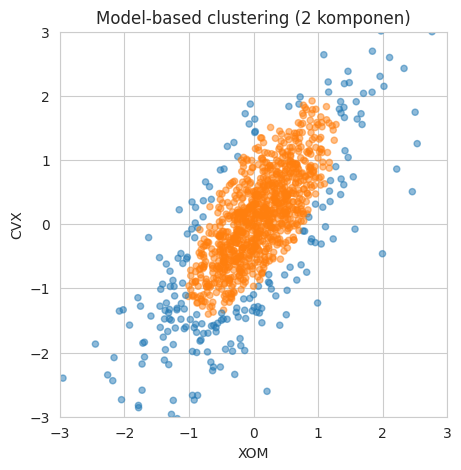

In [19]:
fig, ax = plt.subplots(figsize=(5, 5))
colors = [f"C{c}" for c in mclust.predict(df)]
df.plot.scatter(x="XOM", y="CVX", c=colors, alpha=0.5, ax=ax)
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_title("Model-based clustering (2 komponen)")
plt.show()

Hasilnya sangat berbeda dari K-means dan hierarchical clustering. Ada satu cluster di bagian tengah data dan satu lagi di tepi luar. Itu bukan kesalahan. Tujuan model-based clustering adalah menemukan himpunan distribusi normal yang paling cocok. Return saham sebenarnya punya ekor distribusi yang lebih panjang daripada distribusi normal, jadi metode ini memasang satu distribusi untuk sebagian besar data, lalu distribusi kedua dengan variansi lebih besar untuk menangkap ekornya.

Kita bisa melihat parameter tiap distribusi.

In [20]:
print("Mean")
print(mclust.means_)
print()
print("Covariances")
print(mclust.covariances_)

Mean
[[-0.05031426 -0.21161823]
 [ 0.07246995  0.10494619]]

Covariances
[[[0.97123064 0.97764343]
  [0.97764343 1.67233845]]

 [[0.26822676 0.27562091]
  [0.27562091 0.51679853]]]


Kedua distribusi punya rata-rata dan korelasi yang mirip, tetapi distribusi kedua punya variansi dan kovarians yang jauh lebih besar. Hasil bisa sedikit bervariasi antar-run karena sifat acak algoritma.

### Memilih jumlah cluster dengan BIC

Berbeda dari K-means dan hierarchical clustering, paket `mclust` di R memilih jumlah cluster secara otomatis, lewat **Bayesian Information Criterion (BIC)**. BIC memilih model yang cocok dengan data, dengan penalti untuk banyaknya parameter. Ini perlu karena menambah cluster *selalu* memperbaiki kecocokan, tetapi dengan menambah parameter (risiko overfitting).

Catatan tanda: di paket `mclust`, BIC didefinisikan dengan tanda berlawanan, jadi nilai terbesar yang terbaik. Di `GaussianMixture` BIC didefinisikan seperti biasa, jadi **nilai terkecil yang terbaik**.

`GaussianMixture` tidak mencoba berbagai kombinasi otomatis, jadi kita lakukan sendiri: variasikan jumlah komponen dan jenis kovarians (`full`, `tied`, `diag`, `spherical`). Jenis kovarians menentukan bentuk elips yang diperbolehkan.

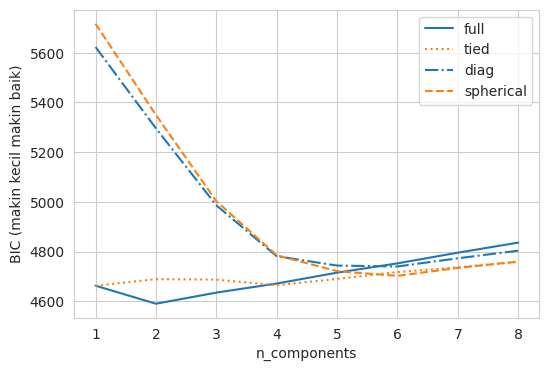

,bic,n_components,covariance_type
4,4589.9289,2,full
8,4634.6363,3,full
1,4662.4795,1,tied
0,4662.4795,1,full
13,4664.5858,4,tied


In [21]:
results = []
covariance_types = ["full", "tied", "diag", "spherical"]

for n_components in range(1, 9):
    for covariance_type in covariance_types:
        gm = GaussianMixture(n_components=n_components, warm_start=True,
                             covariance_type=covariance_type, random_state=1)
        gm.fit(df)
        results.append({
            "bic": gm.bic(df),
            "n_components": n_components,
            "covariance_type": covariance_type,
        })

results = pd.DataFrame(results)

styles = ["C0-", "C1:", "C0-.", "C1--"]
fig, ax = plt.subplots(figsize=(6, 4))
for i, covariance_type in enumerate(covariance_types):
    subset = results.loc[results.covariance_type == covariance_type, :]
    subset.plot(x="n_components", y="bic", ax=ax, label=covariance_type,
                kind="line", style=styles[i])
ax.set_ylabel("BIC (makin kecil makin baik)")
plt.show()

results.sort_values("bic").head(5)

Grafik ini mirip plot elbow K-means, hanya saja yang digambar adalah BIC, bukan persentase varians yang dijelaskan. Di `mclust` ada 14 model kovarians yang dicoba untuk tiap jumlah cluster, sedangkan `GaussianMixture` hanya empat, jadi garisnya lebih sedikit. Menurut BIC di buku, dua komponen sudah cukup untuk data saham ini.

Buku menekankan bahwa model-based clustering adalah bidang yang kaya dan terus berkembang, tetapi mempelajari semua nuansanya mungkin lebih berat daripada yang dibutuhkan kebanyakan masalah data scientist.

**Keterbatasan** model-based clustering:

- Membutuhkan asumsi model untuk data, dan hasilnya sangat bergantung pada asumsi itu.
- Kebutuhan komputasinya lebih besar daripada hierarchical clustering, jadi sulit diskalakan ke data besar.
- Algoritmanya lebih rumit dan kurang mudah dipahami dibanding yang lain.

**Ide kunci:**

- Cluster dianggap berasal dari proses pembangkit data dengan distribusi probabilitas yang berbeda.
- Beberapa model dengan jumlah distribusi (biasanya normal) yang berbeda dicoba.
- Metode memilih model, dan jumlah cluster-nya, yang cocok dengan data tanpa terlalu banyak parameter (menghindari overfitting).

## 5. Scaling dan Variabel Kategorikal

Teknik unsupervised umumnya mengharuskan data diskalakan dengan benar. Ini berbeda dari banyak teknik regresi dan klasifikasi yang tidak peduli skala (pengecualiannya K-Nearest Neighbors).

Istilah penting:

- **Scaling**: mengecilkan atau melebarkan data agar beberapa variabel berada pada skala yang sama.
- **Normalization (standardization)**: kurangi rata-rata, bagi simpangan baku.
- **Gower's distance**: algoritma penskalaan untuk data campuran numerik dan kategorikal, yang membawa semua variabel ke rentang 0 sampai 1.

### Mengapa skala penting? Analogi

Bayangkan kita mengukur kemiripan dua orang dari tinggi badan (dalam sentimeter, selisih belasan) dan gaji (dalam rupiah, selisih jutaan). Gaji akan menenggelamkan tinggi badan sepenuhnya. Itu yang terjadi pada PCA dan K-means kalau data tidak diskalakan: variabel berangka besar mendominasi, dan variabel berangka kecil diabaikan.

Mari buktikan dengan data pinjaman gagal bayar.

In [22]:
defaults = loan_data.loc[loan_data["outcome"] == "default", :]
columns = ["loan_amnt", "annual_inc", "revol_bal", "open_acc", "dti", "revol_util"]
df = defaults[columns]

# K-means TANPA scaling
kmeans = KMeans(n_clusters=4, n_init=10, random_state=1).fit(df)
counts = Counter(kmeans.labels_)

centers = pd.DataFrame(kmeans.cluster_centers_, columns=columns)
centers["size"] = [counts[i] for i in range(4)]
centers

,loan_amnt,annual_inc,revol_bal,open_acc,dti,revol_util,size
0,10622.7427,42577.4689,10301.7190,9.5945,17.7081,58.1251,13949
1,18312.3585,83793.8036,19740.5727,11.6778,16.7719,62.3072,7509
2,21924.5895,166721.9162,39129.9905,12.5661,13.3745,63.5052,1161
3,22570.1923,489783.4038,85161.3462,13.3269,6.9075,59.6519,52


Terlihat bahwa `annual_inc` dan `revol_bal` mendominasi pembentukan cluster, dan ukuran cluster sangat timpang. Di buku, satu cluster hanya berisi 52 anggota dengan pendapatan dan saldo kredit yang relatif tinggi.

Solusi yang umum: ubah ke **z-score** (kurangi rata-rata, bagi simpangan baku): z = (x − rata-rata) / simpangan baku.

In [23]:
scaler = preprocessing.StandardScaler()
df0 = scaler.fit_transform(df * 1.0)

kmeans = KMeans(n_clusters=4, n_init=10, random_state=1).fit(df0)
counts = Counter(kmeans.labels_)

# Kembalikan pusat cluster ke satuan asli supaya mudah dibaca
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=columns)
centers["size"] = [counts[i] for i in range(4)]
centers

,loan_amnt,annual_inc,revol_bal,open_acc,dti,revol_util,size
0,25911.9180,116436.1835,32850.1992,12.4172,16.1997,66.0754,3704
1,10353.6833,53506.6684,6049.6985,8.6999,11.3478,30.5781,5306
2,13394.4237,55638.6230,16409.3562,14.2359,24.2329,59.7590,6292
3,10475.3524,51152.6176,11505.2371,7.4731,15.7540,77.6540,7369


Sekarang ukuran cluster jauh lebih seimbang dan cluster tidak lagi didominasi `annual_inc` dan `revol_bal`, sehingga struktur data yang lebih menarik terlihat. Pusat cluster dikembalikan ke satuan asli dengan `inverse_transform`; kalau dibiarkan sebagai z-score, nilainya lebih sulit ditafsirkan.

Penskalaan juga penting untuk PCA. Memakai z-score setara dengan memakai matriks **korelasi** alih-alih matriks **kovarians** saat menghitung komponen.

### Variabel yang mendominasi

Walaupun semua variabel berskala sama dan mencerminkan kepentingan relatif dengan benar (misalnya pergerakan harga saham), kadang tetap perlu menskalakan ulang. Misalnya kita tambahkan Google (GOOGL) dan Amazon (AMZN) ke analisis PCA tadi.

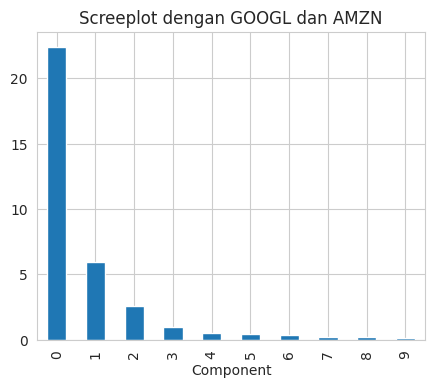

,0,1
GOOGL,0.857,-0.478
AMZN,0.445,0.874
AAPL,0.072,0.021
MSFT,0.036,0.006
CSCO,0.029,0.003
INTC,0.027,0.006
CVX,0.090,0.037
XOM,0.080,0.021
SLB,0.110,0.030
COP,0.058,0.024


In [24]:
syms2 = ["GOOGL", "AMZN", "AAPL", "MSFT", "CSCO", "INTC", "CVX", "XOM",
         "SLB", "COP", "JPM", "WFC", "USB", "AXP", "WMT", "TGT", "HD", "COST"]
top_sp1 = sp500_px.loc[sp500_px.index >= "2005-01-01", syms2]

sp_pca1 = PCA()
sp_pca1.fit(top_sp1)

explained_variance = pd.DataFrame(sp_pca1.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(5, 4))
ax.set_xlabel("Component")
ax.set_title("Screeplot dengan GOOGL dan AMZN")
plt.show()

loadings = pd.DataFrame(sp_pca1.components_[0:2, :], columns=top_sp1.columns)
loadings.transpose().round(3)

Screeplot memperlihatkan varians komponen pertama dan kedua jauh lebih besar dari yang lain, tanda khas bahwa satu atau dua variabel mendominasi. Benar saja, dua komponen pertama hampir sepenuhnya ditentukan oleh GOOGL dan AMZN, karena pergerakan harga kedua saham itu begitu besar.

Cara menanganinya: masukkan apa adanya, skalakan ulang variabelnya, atau keluarkan variabel dominan dari analisis dan tangani terpisah. Tidak ada pendekatan yang "benar" untuk semua kasus, semuanya tergantung tujuan analisis.

### Data kategorikal dan Gower's distance

Data kategorikal harus diubah menjadi angka dulu: lewat urutan peringkat (untuk faktor berurutan) atau dummy variable (one hot encoding). Kalau datanya campuran kontinu dan biner, variabel biasanya perlu diskalakan agar rentangnya mirip. Salah satu metode populer adalah **Gower's distance**.

Idenya: pakai ukuran jarak berbeda untuk tiap jenis variabel.

- Variabel numerik dan faktor berurutan: nilai absolut selisih dua record (jarak Manhattan).
- Variabel kategorikal: jarak 1 kalau kategorinya berbeda, 0 kalau sama.

Langkah menghitungnya:

1. Hitung jarak untuk tiap pasangan record pada tiap variabel.
2. Skalakan tiap jarak variabel agar minimum 0 dan maksimum 1.
3. Jumlahkan (rata-rata, boleh berbobot) jarak yang sudah diskalakan itu untuk membentuk matriks jarak.

Buku mencatat bahwa saat ditulis, Gower's distance belum ada di paket Python populer (di R ada `daisy` dari paket `cluster`). Karena itu kita buat fungsi sederhananya sendiri dan mencobanya pada lima pinjaman.

In [25]:
def gower_distance(data):
    """Gower's distance sederhana: numerik = selisih absolut dibagi rentang, kategorikal = 0/1."""
    n = len(data)
    total = np.zeros((n, n))
    for col in data.columns:
        s = data[col]
        if pd.api.types.is_numeric_dtype(s):
            v = s.values.astype(float)
            rng = v.max() - v.min()
            d = np.abs(v[:, None] - v[None, :]) / (rng if rng > 0 else 1)
        else:
            v = s.astype(str).values
            d = (v[:, None] != v[None, :]).astype(float)
        total += d
    return total / data.shape[1]


x = loan_data.loc[loan_data.index[:5], ["dti", "payment_inc_ratio", "home_", "purpose_"]]
print(x)
print()
print(pd.DataFrame(gower_distance(x), index=x.index, columns=x.index).round(3))

     dti  payment_inc_ratio home_            purpose_
1   1.00             2.3932  RENT      major_purchase
2   5.55             4.5717   OWN      small_business
3  18.08             9.7160  RENT               other
4  10.08            12.2152  RENT  debt_consolidation
5   7.06             3.9089  RENT               other

       1      2      3      4      5
1  0.000  0.622  0.686  0.633  0.377
2  0.622  0.000  0.814  0.761  0.539
3  0.686  0.814  0.000  0.431  0.309
4  0.633  0.761  0.431  0.000  0.506
5  0.377  0.539  0.309  0.506  0.000


Semua jarak berada di antara 0 dan 1. Pasangan record dengan jarak terbesar adalah yang tidak punya nilai `home_` dan `purpose_` sama, serta punya `dti` dan `payment_inc_ratio` yang sangat berbeda. Pasangan dengan jarak terkecil adalah yang berbagi nilai kategori yang sama.

Matriks jarak Gower ini bisa dimasukkan ke hierarchical clustering. Dengan `scipy`, matriks jarak penuh harus diubah dulu ke bentuk ringkas (`squareform`).

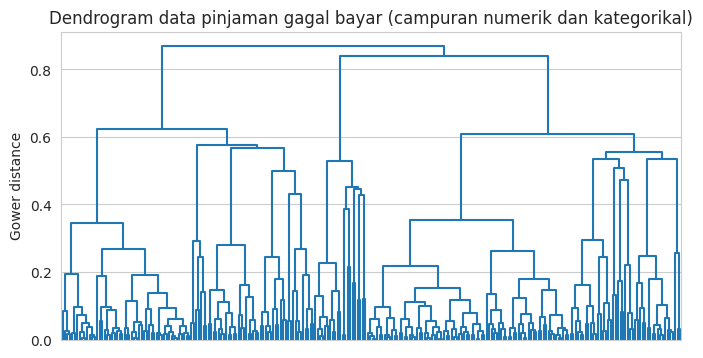

,n,dti_rata2,home_terbanyak,purpose_terbanyak
group,,,,
1,52,18.4850,MORTGAGE,debt_consolidation
2,7,11.1171,MORTGAGE,small_business
3,21,20.7067,MORTGAGE,credit_card
4,22,16.4014,MORTGAGE,other
5,11,20.9136,OWN,debt_consolidation
6,10,11.1410,OWN,home_improvement
7,82,17.6145,RENT,debt_consolidation
8,17,13.8976,RENT,other
9,2,14.1400,RENT,home_improvement


In [26]:
from scipy.spatial.distance import squareform

sample = defaults.sample(250, random_state=1)[["dti", "payment_inc_ratio", "home_", "purpose_"]]

d = gower_distance(sample)
Zg = linkage(squareform(d, checks=False), method="complete")

fig, ax = plt.subplots(figsize=(8, 4))
dendrogram(Zg, no_labels=True, ax=ax, color_threshold=0)
ax.set_ylabel("Gower distance")
ax.set_title("Dendrogram data pinjaman gagal bayar (campuran numerik dan kategorikal)")
plt.show()

# Ambil cluster pada ambang 0.5 dan lihat isinya
groups = fcluster(Zg, 0.5, criterion="distance")
sample.assign(group=groups).groupby("group").agg(
    n=("dti", "size"),
    dti_rata2=("dti", "mean"),
    home_terbanyak=("home_", lambda s: s.value_counts().idxmax()),
    purpose_terbanyak=("purpose_", lambda s: s.value_counts().idxmax()),
).head(10)

Di buku, salah satu subtree seluruhnya berisi pemilik rumah dengan tujuan pinjaman `debt_consolidation`. Tidak semua subtree serapi itu, tetapi ini menunjukkan bahwa variabel kategorikal cenderung mengelompok dalam cluster.

### Masalah clustering data campuran

K-means dan PCA paling cocok untuk variabel kontinu. Untuk dataset kecil, lebih baik pakai hierarchical clustering dengan Gower's distance. Secara prinsip K-means boleh dipakai untuk data biner atau kategorikal lewat one hot encoding, tetapi praktiknya sulit.

Masalahnya: kalau memakai z-score standar, variabel biner akan mendominasi pembentukan cluster. Variabel 0/1 hanya punya dua nilai, jadi K-means bisa memperkecil jumlah kuadrat dalam cluster dengan cara memasukkan semua record bernilai 0 (atau 1) ke satu cluster. Mari lihat buktinya.

In [27]:
columns = ["dti", "payment_inc_ratio", "home_", "pub_rec_zero"]
df = pd.get_dummies(defaults[columns])

scaler = preprocessing.StandardScaler()
df0 = scaler.fit_transform(df * 1.0)

kmeans = KMeans(n_clusters=4, n_init=10, random_state=1).fit(df0)
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=df.columns)
centers.round(2)

,dti,payment_inc_ratio,pub_rec_zero,home__MORTGAGE,home__OWN,home__RENT
0,17.46,8.42,1.00,1.00,-0.0,0.00
1,16.99,9.11,1.00,0.00,-0.0,1.00
2,17.20,9.27,0.92,0.00,1.0,0.00
3,16.50,8.06,-0.00,0.52,-0.0,0.48


Empat cluster teratas pada dasarnya hanya menjadi wakil dari tingkat-tingkat variabel faktor (misalnya cluster pemilik rumah, cluster penyewa, dan seterusnya), sementara `dti` dan `payment_inc_ratio` hampir sama di semua cluster.

Cara menghindarinya:

- Skalakan variabel biner agar variansnya lebih kecil daripada variabel lain.
- Untuk data yang sangat besar, jalankan clustering terpisah pada subset dengan nilai kategorikal tertentu, misalnya terpisah untuk peminjam dengan hipotek, pemilik rumah penuh, dan penyewa.

**Ide kunci:**

- Variabel dengan skala atau satuan berbeda perlu diubah ke skala yang sama supaya pengaruhnya tidak ditentukan oleh skalanya.
- Metode umum: normalisasi (standardisasi), yaitu kurangi rata-rata dan bagi simpangan baku.
- Metode lain: Gower's distance, yang menskalakan semua variabel ke rentang 0 sampai 1 dan sering dipakai untuk data campuran numerik dan kategorikal.

## Poin-poin Penting Bab 7

- **Unsupervised learning** mencari pola dalam data tanpa variabel jawaban. Kegunaannya: clustering, reduksi dimensi, eksplorasi, dan membantu masalah cold start.
- **PCA** merangkum variabel numerik yang saling berkaitan menjadi sedikit komponen yang tidak berkorelasi. Screeplot dan loadings dipakai untuk memilih jumlah komponen dan menafsirkannya. Untuk data kategorikal ada correspondence analysis.
- **K-means** membagi data ke K cluster dengan meminimalkan jarak ke pusat cluster. Ia cepat dan skalabel, tetapi K harus ditentukan (elbow method sebagai panduan) dan hasilnya bergantung pada titik awal acak.
- **Hierarchical clustering** menggabungkan record dari bawah ke atas dan menghasilkan dendrogram, tanpa perlu menentukan K di awal. Hasilnya sangat bergantung pada ukuran dissimilarity (complete, single, average, Ward), dan metodenya kurang cocok untuk data besar.
- **Model-based clustering** menganggap cluster sebagai distribusi normal multivariat dan memilih model lewat BIC. Pendekatannya lebih kuat secara statistik, tetapi bergantung asumsi dan berat secara komputasi.
- **Scaling** sangat penting. Tanpa standardisasi, variabel berangka besar mendominasi PCA dan K-means. Untuk data campuran, Gower's distance dengan hierarchical clustering lebih tepat daripada K-means.
- Pada data bising, metode yang berbeda dapat memberi hasil yang sangat berbeda. Tidak ada aturan sederhana untuk memilih. Pilihan bergantung pada ukuran data dan tujuan analisis.

Referensi: Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists*, 2nd ed., Bab 7 "Unsupervised Learning". O'Reilly Media.